# 선택: 학습 시작 ⏱️

타이머를 쓰려면 아래 셀을 실행해요. 처음에만 시작을 기록하고 다시 실행하면 기존 기록을 보여줘요. 쉬는 시간도 포함해요. 사용하지 않아도 문제를 풀 수 있어요. 노트북 작업 폴더는 Day19 폴더 또는 그 부모여야 해요.


In [ ]:
# 이 셀은 커널을 다시 시작한 뒤에도 독립적으로 작동해요.
from pathlib import Path

_cwd = Path.cwd()
_dirs = [
    p
    for p in (_cwd, _cwd / "day19-time-distance-graphs")
    if p.name == "day19-time-distance-graphs"
    and p.is_dir()
    and (p / "day19.ipynb").is_file()
    and (p / "study_timer.py").is_file()
]
if (
    len(_dirs) != 1
    or _dirs[0].is_symlink()
    or (_dirs[0] / "day19.ipynb").is_symlink()
    or (_dirs[0] / "study_timer.py").is_symlink()
):
    print("교재 폴더를 하나로 확인할 수 없어요. Day19 폴더에서 노트북을 열어 주세요.")
else:
    # 검증한 파일을 메모리에서 읽고 실행해요. 임포트 캐시는 만들지 않아요.
    _helper = _dirs[0] / "study_timer.py"
    _timer = {"__name__": "day19_timer"}
    try:
        exec(compile(_helper.read_bytes(), str(_helper), "exec"), _timer)
    except (OSError, SyntaxError):
        print("타이머 도구를 읽을 수 없어요. 기록을 바꾸지 않고 함께 확인해 주세요.")
    else:
        _timer["action"]("start")

# Day19 | 로봇 기록을 시간 그래프로 읽어요

2026-11-07 · Physical AI · 목표 약 60분 (실제 시간은 다를 수 있어요)

오늘은 이미 완성한 Day18 A/B 시뮬레이션을 다시 만들지 않고 그 기록을 그림으로 바꿔요. 이 기록은 프로그램이 계산한 **시뮬레이션 기록**이며 실제 센서 측정값이 아니에요. **목표:** (1) 같은 시각과 거리를 짝짓기 (2) 같은 시각의 두 결과 비교 (3) 시간-거리 그래프 읽기 (4) 조건을 바꿔 예상과 결과 비교 (5) 잘못 붙인 시각 고치기. 정답과 해설은 헴이 시도한 뒤 함께 확인해요.

**선택 타이머:** ① 맨 위 시작 셀 실행 → ② 문제 풀기 → ③ 맨 아래 종료 셀 실행 후 `종료` 입력 → ④ Ctrl+S로 노트북 저장 → ⑤ 이 대화에 ‘다 풀었어’라고 알려주기. 타이머 없이도 풀 수 있어요. 휴식과 노트북을 닫은 시간이 포함된 경과 시간이에요. 종료 셀을 실행한 시각은 저장·채팅 발송 시각과 달라요. 노트북은 채팅 발송을 감지하지 못해요. **모두 실행**을 누르면 종료 셀도 실행되므로 입력창에서 `종료`를 입력하지 않으면 기록을 끝내지 않아요.

**잠정 순서:** 선택과 그림 10분, 기존 기록 정리 15분, 그래프와 비교 15분, 조건 변경과 디버깅 15분, 돌아보기 5분. 오늘은 적용·구현·변형·설명을 함께 연습해요. 8주는 개인 계획을 조정할 목표일 뿐 보장된 수료일이 아니에요. 실제 시간과 막힌 곳을 알려주면 다음 분량을 조절할게요.


## 1 | 어디서 시작할까요? (선택)

어제 미리보기는 아직 답하지 않았으니, 알고 있다고 가정하지 않아요. 아래 확인을 읽고 **그림 먼저** 또는 **바로 실습** 중 하나를 골라요. 둘 다 아래 필수 문제를 풀어요. 그림 먼저는 2절을 천천히 읽고, 바로 실습은 필요할 때 2절로 돌아와도 돼요.

### 확인 문제 1 · 필수

두 로봇이 2.0초에 이동을 시작했어요. A는 0.5초 이동 후 거리가 0.9m이고, B는 1.0초 이동 후 거리가 0.6m예요. 이동 후 거리와 짝인 시각을 각각 구하고 같은 시각인지 적으세요. **답할 곳:** 아래 빈칸 또는 노트북의 이 문제 아래 Markdown 셀.

- 내 선택: 그림 먼저 / 바로 실습
  A: 2.5초에 벽까지 0.9m 남음 → (2.5초, 0.9m)
  B: 3.0초에 벽까지 0.6m 남음 → (3.0초, 0.6m)
- 두 점이 같은 시각인가요? 아니요. A는 2.5초에 확인한 점이고, B는 3.0초에 확인한 점이므로 서로 다른 시각입니다.


## 2 | 시간표의 짝을 지켜요

**개념 · 쉬운 뜻:** 시간이 흐를 때 벽과 로봇 사이가 얼마나 남았는지 점으로 그려요. **비유:** 달리기 선수가 출발한 뒤 시간을 재고, 각 시각에 남은 거리를 적는 시간표예요. **실제 용어:** 가로축은 시간(s, 초), 세로축은 벽까지 거리(m, 미터)인 시간-거리 그래프예요. 오른쪽은 더 나중, 아래쪽은 벽에 더 가까움이에요.

![이동 전과 이동 후의 시각과 거리를 각각 짝짓는 그림](assets/01-pairs.svg)

**예제:** 어떤 이동이 1.0초에 시작해 0.5초 걸리고, 벽까지 거리가 1.5m에서 1.25m가 됐어요. 이동 전 점은 (1.0초, 1.5m), 이동 후 점은 (1.5초, 1.25m)예요. `1.0 + 0.5 = 1.5`이므로 이동 후 거리를 1.0초에 붙이면 안 돼요. 숫자는 예시예요.

**Day18 이름표:** `t_s`는 이동 전 시각(초), `front_m`은 그때 앞쪽 벽까지 거리(m), `next_t_s`는 이동 후 시각(초), `next_front_m`은 이동 후 거리(m)예요. `action`은 GO/STOP 판단이에요. `dt_s`는 다시 확인하기 전 이동 시간(초)이에요. A와 B 모두 단위는 초이고 간격만 각각 0.5초와 1.0초예요.

**주의:** STOP 행은 더 이동하지 않고 시각과 거리도 그대로예요. 이전 GO 행의 이동 후 점과 다음 행의 이동 전 점은 같은 상태일 수 있어요. 선을 그릴 때 겹치는 점을 여러 번 넣지 않도록 시작점 하나와 각 GO의 이동 후 점을 써요.


## Day18 함수 준비 코드

Day18 노트북의 완성된 `run_sim` 함수 셀 내용을 여기에 복사해 붙여넣고 실행해요. 기존 노트북은 수정하지 않아요.


In [ ]:
def run_sim(dt_s):
    # dt_s: 다시 판단하기 전까지 한 번 이동할 시간(초)
    x_m = 0.0  # 이동 전 로봇 위치(m), 매 실험 0부터 시작
    wall_m = 2.0  # 움직이지 않는 앞쪽 벽 위치(m)
    stop_m = 0.75  # 이 거리 이하이면 STOP으로 판단(m)
    cruise_mps = 0.5  # GO일 때 사용할 속도(m/s)
    rows = []  # 이동 전 / 후를 함께 남길 기록장
    for step in range(20):  # 최대 20번만 판단해요
        t_s = step * dt_s  # 이번 판단을 하는 시간(초)
        front_m = wall_m - x_m  # 이동 전 벽까지 거리(m)
        action = "STOP" if front_m <= stop_m else "GO"
        speed_mps = 0.0 if action == "STOP" else cruise_mps
        next_x_m = x_m + speed_mps * dt_s  # 이동 후 위치(m)
        next_front_m = wall_m - next_x_m  # 이동 후 벽까지 거리(m)
        # STOP 행은 움직이지 않고 기록을 끝내므로 시간도 그대로예요
        next_t_s = t_s if action == "STOP" else t_s + dt_s
        rows.append(
            {
                "t_s": t_s,
                "x_m": x_m,
                "front_m": front_m,
                "action": action,
                "speed_mps": speed_mps,
                "next_t_s": next_t_s,
                "next_x_m": next_x_m,
                "next_front_m": next_front_m,
            }
        )
        # 새 위치를 다음 반복의 출발 위치로 저장해요
        x_m = next_x_m
        if action == "STOP":  # 첫 STOP을 기록했으면 반복을 끝내요
            break
    return rows

## 3 | 기존 시뮬레이션 기록을 점으로 만들어요

Day18 노트북의 완성된 `run_sim` 함수 셀을 복사해 Day19 노트북의 준비 코드 칸에 붙여 실행해요. 함수 안의 규칙은 고치지 않아요. 그 다음 아래 코드를 실행해 A/B 기록을 다시 얻어요. 문제가 생기면 오류 문장과 함께 알려주세요.


In [ ]:
# A와 B가 앞을 다시 확인하는 간격(초)만 달라요.
rows_a = run_sim(0.5)
rows_b = run_sim(1.0)
print("A 첫 행:", rows_a[0])
print("B 첫 행:", rows_b[0])

A 첫 행: {'t_s': 0.0, 'x_m': 0.0, 'front_m': 2.0, 'action': 'GO', 'speed_mps': 0.5, 'next_t_s': 0.5, 'next_x_m': 0.25, 'next_front_m': 1.75}
B 첫 행: {'t_s': 0.0, 'x_m': 0.0, 'front_m': 2.0, 'action': 'GO', 'speed_mps': 0.5, 'next_t_s': 1.0, 'next_x_m': 0.5, 'next_front_m': 1.5}


**작은 예제:** 장보기 목록에서 이름과 개수를 한 쌍으로 만들어요. `append`는 목록 끝에 하나를 넣어요. 이건 아래 문제의 답이 아니라 짝짓기 연습이에요.


In [ ]:
items = [{"name": "apple", "count": 2}, {"name": "pear", "count": 3}]
pairs = []  # (이름, 개수)를 담을 빈 목록
for item in items:
    pairs.append((item["name"], item["count"]))
print(pairs)

[('apple', 2), ('pear', 3)]


### 확인 문제 2 · 필수: 점 목록 직접 만들기

아래 `make_points` 함수의 `...` 네 곳을 채우세요. **계약:** 입력 `rows`는 Day18의 판단 행 목록, 출력은 `(시각(초), 벽까지 거리(m))` 쌍의 목록이에요. 첫 점은 첫 행의 **이동 전** 시각·거리예요. 그다음 GO 행마다 **이동 후** 시각·거리 한 점을 순서대로 추가해요. STOP은 추가하지 않아요. 예제의 `append`를 써도 좋아요. 코드를 완성해 실행하고 A/B의 첫 점과 마지막 점을 살펴보세요. **답할 곳:** 아래 코드 셀과 노트북의 빈칸.


In [ ]:
def make_points(rows):
    # 첫 판단의 이동 전 시각(초)과 벽까지 거리(m)를 첫 점으로 넣어요.
    points = [(rows[0]["t_s"], rows[0]["front_m"])]
    for row in rows:  # row는 판단과 이동 전후가 함께 든 한 행
        if row["action"] == "GO":
            # 이동 후 시각(초)과 그때 거리(m)를 짝지어 추가해요.
            points.append((row["next_t_s"], row["next_front_m"]))
    return points


# A 첫 행: {'t_s': 0.0, 'x_m': 0.0, 'front_m': 2.0, 'action': 'GO', 'speed_mps': 0.5, 'next_t_s': 0.5, 'next_x_m': 0.25, 'next_front_m': 1.75}


points_a = make_points(rows_a)
points_b = make_points(rows_b)
print("A 점:", points_a)
print("B 점:", points_b)

A 점: [(0.0, 2.0), (0.5, 1.75), (1.0, 1.5), (1.5, 1.25), (2.0, 1.0), (2.5, 0.75)]
B 점: [(0.0, 2.0), (1.0, 1.5), (2.0, 1.0), (3.0, 0.5)]


### 확인 문제 3 · 필수

A 기록에서 이동 전 시각이 1.0초인 행을 찾으세요.  
그 행의 이동 전과 이동 후 시각·벽까지 거리, 그리고 둘을 각각 점 `(시각, 거리)`으로 적으세요. **답할 곳:** 노트북 이 문제 아래 빈칸.

- 이동 전: 1.0초, 0.5m → (1.0, 0.5)
- 이동 후: 1.5초, 0.75m → (1.5, 0.75)
- 왜 `t_s`와 `next_front_m`을 한 쌍으로 쓰면 안 되나요?
  - `next_front_m`은 이 후에 남은 거리니까?

### 확인 문제 4 · 필수

`make_points`가 만든 A와 B의 첫 점과 마지막 점을 각각 출력에서 찾아 적으세요. 마지막 점과 각 기록의 첫 STOP 행을 비교해 같은 상태인지 적고, STOP을 다시 추가하지 않은 이유를 설명하세요. **답할 곳:** 노트북 아래 빈칸.

- A 첫 점 (0.0, 0.0) / 마지막 점 (2.5, 1.25) / 첫 STOP 행 시각·거리 (2.5, 1.25)
- B 첫 점 (0.0, 0.0) / 마지막 점 (3.0, 1.5) / 첫 STOP 행 시각·거리 (3.0, 1.5)
- 같은 상태인가요? 아니 / STOP을 중복 추가하지 않는 이유: 마지막 GO에서 도착한 위치와 바로 다움 STOP을 판단한 위치는 같다. STOP에서는 움직이지 않으므로 이미 그래프에 있는 점을 다시 추가하지 않는다.


## 4 | 그래프와 같은 시각 비교

![두 축과 한 점을 읽는 예시 그림](assets/02-graph.svg)

이 노트북 환경에는 그래프 패키지 matplotlib이 없어요.

> 없으면 설치하는것도 알려주고 해야하지않겠움?

설치하지 않고, 이미 사용하는 노트북의 화면 표시 기능과 Python으로 그림을 그려요. 아래 코드는 **제공된 화면 표시 도구**예요. 내부를 직접 구현하지 않아도 돼요. 코드를 실행하면 `draw_graph`라는 그리기 도구가 생기고 A/B 그래프가 보여요. 가로축은 초, 세로축은 미터예요. 점은 **시뮬레이션 기록**이에요. 선은 그 점 사이를 직선으로 이은 그림이며 점이 없는 곳에 별도의 기록이나 실제 센서 측정이 있었다는 뜻이 아니에요.


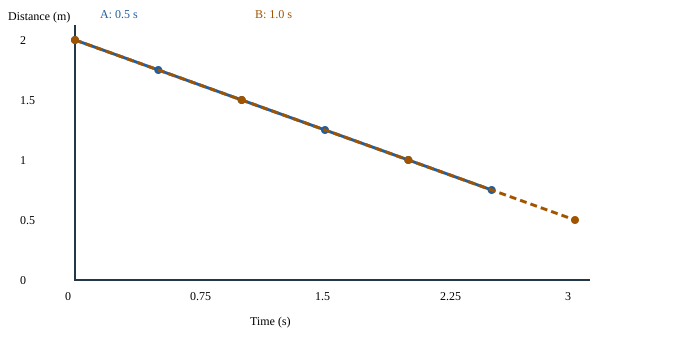

In [ ]:
from html import escape  # 글자가 그림 형식을 깨지 않게 보호해요

from IPython.display import SVG, display  # 노트북에 이미 있는 그림 표시 도구


def draw_graph(series):
    # series: (이름, 점 목록)들의 목록. 점은 (시각 초, 거리 m)이에요.
    xmax = max(t for _, pts in series for t, d in pts) or 1  # 가장 큰 시각(초)
    ymax = max(d for _, pts in series for t, d in pts) or 1  # 가장 큰 거리(m)

    # 화면 안의 위치로 바꿔요: 시간은 오른쪽, 거리는 위쪽이 커요.
    def xy(t, d):
        return 75 + 500 * t / xmax, 280 - 240 * d / ymax

    parts = [
        '<svg xmlns="http://www.w3.org/2000/svg" width="700" height="340" viewBox="0 0 700 340">',
        '<rect width="700" height="340" fill="white"/>',
        '<path d="M75 25 V280 H590" fill="none" stroke="#243746" stroke-width="2"/>',
        '<text x="250" y="325">Time (s)</text><text x="8" y="20">Distance (m)</text>',
    ]
    for i in range(5):
        x, _ = xy(xmax * i / 4, 0)
        _, y = xy(0, ymax * i / 4)
        parts.append(f'<text x="{x-10:.1f}" y="300">{xmax*i/4:g}</text>')
        parts.append(f'<text x="20" y="{y+4:.1f}">{ymax*i/4:g}</text>')
    colors = ["#225d9c", "#a15400", "#207850", "#764ca0"]
    for i, (name, pts) in enumerate(series):
        color = colors[i % len(colors)]
        coords = [xy(t, d) for t, d in pts]
        line = " ".join(f"{x:.2f},{y:.2f}" for x, y in coords)
        dash = ' stroke-dasharray="7 4"' if i % 2 else ""
        parts.append(
            f'<polyline points="{line}" fill="none" stroke="{color}" stroke-width="3"{dash}/>'
        )
        for x, y in coords:
            parts.append(f'<circle cx="{x:.2f}" cy="{y:.2f}" r="4" fill="{color}"/>')
        parts.append(
            f'<text x="{100+i*155}" y="18" fill="{color}">{escape(name)}</text>'
        )
    display(SVG("".join(parts) + "</svg>"))


draw_graph([("A: 0.5 s", points_a), ("B: 1.0 s", points_b)])

### 확인 문제 5 · 필수

두 시뮬레이션 기록에 **모두 있는 같은 시각** 1.0초와 2.0초를 골라 A와 B의 거리를 각각 읽어 표에 적으세요. 같은 시각인지 확인하는 이유를 한 문장으로 쓰세요. 한 기록에만 있는 시각은 다른 시뮬레이션에도 기록이 있는 것처럼 비교하지 않아요. **답할 곳:** 노트북 아래 빈칸.

A 점: [(0.0, 0.0), (0.5, 0.25), (1.0, 0.5), (1.5, 0.75), (2.0, 1.0), (2.5, 1.25)]
B 점: [(0.0, 0.0), (1.0, 0.5), (2.0, 1.0), (3.0, 1.5)]

| 시각  | A 거리 | B 거리 |
| ----- | ------ | ------ |
| 1.0초 | 0.5 m  | 0.5 m  |
| 2.0초 | 1.0 m  | 1.0 m  |

- 같은 시각에 비교하는 이유: 서로 다른 시간때문에 생긴 거리 차이를 섞지않고 비교하기 위해서

### 확인 문제 6 · 필수

그래프를 보고 A와 B 각각 첫 STOP 시각과 그때 거리를 기록에서 찾아 적으세요. 어느 점까지 선이 이어지는지 설명하고, 두 STOP 시각의 차이가 **시간 단위가 아니라 무엇의 차이**에서 오는지 쓰세요. **답할 곳:** 노트북 아래 빈칸.

- A: 2.5초, 1.25m / B: 3.0초, 1.5m
- 선의 끝과 STOP의 관계: 선의 끝이 STOP이지
- 차이가 생긴 이유: 다음 스텝이 달라서?


## 5 | 조건을 바꾸고 예상해요

**실습:** Day18의 `run_sim`은 판단 간격 `dt_s`만 인자로 받아요. 함수를 다시 쓰거나 기존 파일을 바꾸지 않고, 이번에는 새 실험 C에서 간격만 0.25초로 바꿔 호출해요. 시작 위치·벽 위치·GO 속도·STOP 기준은 그대로예요.

### 확인 문제 7 · 필수: 두 가지 간격 실험

실행하기 **전**에 C가 A보다 같은 시간 동안 더 자주 확인할지, 첫 STOP 시각도 반드시 달라질지 예상하고 이유를 적으세요. 그런 다음 아래 코드의 빈칸에 간격을 넣고 실행해 시뮬레이션 점과 그래프를 만드세요. 첫 STOP 시각이 다르거나 같을 수 있는 이유를 **STOP 기준에 도달하는 시각과 확인 시각의 관계**로 설명하세요. **답할 곳:** 노트북 아래 빈칸과 코드 셀.


[(0.0, 2.0), (0.25, 1.875), (0.5, 1.75), (0.75, 1.625), (1.0, 1.5), (1.25, 1.375), (1.5, 1.25), (1.75, 1.125), (2.0, 1.0), (2.25, 0.875), (2.5, 0.75)]
C 첫 STOP: {'t_s': 2.5, 'x_m': 1.25, 'front_m': 0.75, 'action': 'STOP', 'speed_mps': 0.0, 'next_t_s': 2.5, 'next_x_m': 1.25, 'next_front_m': 0.75}


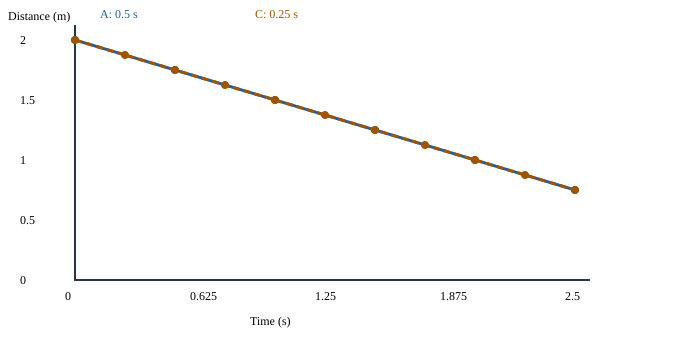

In [ ]:
# C의 확인 간격을 초 단위로 넣어요.
rows_c = run_sim(0.25)  # 여기에 0.25를 넣으세요
points_c = make_points(rows_c)
print(points_c)
print("C 첫 STOP:", next(row for row in rows_c if row["action"] == "STOP"))
draw_graph([("A: 0.5 s", points_a), ("C: 0.25 s", points_c)])

# A 점: [(0.0, 0.0), (0.5, 0.25), (1.0, 0.5), (1.5, 0.75), (2.0, 1.0), (2.5, 1.25)]
# B 점: [(0.0, 0.0), (1.0, 0.5), (2.0, 1.0), (3.0, 1.5)]

- 실행 전 예상과 이유 (확인 횟수 / 첫 STOP): \_\_\_ ?? 뭐적으라는지 잘 모르겠어 너가채워
- C 첫 STOP: 2.5초 / 1.25m
- 예상과 결과를 비교하면: **_ / 더 자주 확인해도 첫 STOP이 항상 달라지지 않는 이유: _** stop 조건은 항상 같으니까
- 공통 시각 ***초 / A ***m / C \_\_\_m 공통시각이라는게 뭘말하는거야? 2.5?|

**두 번째 실험 D:** 이번에는 기존 함수를 바꾸지 않고 `run_sim(0.75)`를 호출해요. A와 D가 같은 시각 0초와 1.5초에 남긴 시뮬레이션 거리와, 각자의 첫 STOP을 아래에 적어요. 1.5초 이후 A와 D의 첫 STOP이 서로 다른 시각이면 그 STOP 거리끼리는 **같은 시각 비교가 아니라는 점**도 적어요. 기준에 도달하는 시각이 확인 시각과 꼭 맞지 않을 때 왜 다음 확인까지 기다려야 하는지 생각해요.


D의 시뮬레이션 점: [(0.0, 2.0), (0.75, 1.625), (1.5, 1.25), (2.25, 0.875), (3.0, 0.5)]
D 첫 STOP: {'t_s': 3.0, 'x_m': 1.5, 'front_m': 0.5, 'action': 'STOP', 'speed_mps': 0.0, 'next_t_s': 3.0, 'next_x_m': 1.5, 'next_front_m': 0.5}


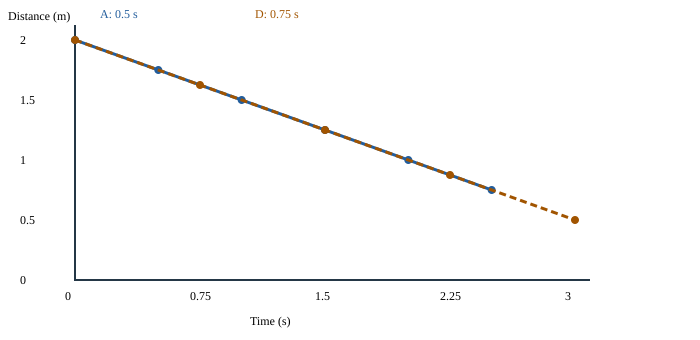

In [ ]:
# D는 0.75초마다 다시 확인해요. 위치·속도·기준은 A와 같아요.
rows_d = run_sim(0.75)
points_d = make_points(rows_d)
print("D의 시뮬레이션 점:", points_d)
print("D 첫 STOP:", next(row for row in rows_d if row["action"] == "STOP"))
draw_graph([("A: 0.5 s", points_a), ("D: 0.75 s", points_d)])

In [ ]:
# A 점: [(0.0, 0.0), (0.5, 0.25), (1.0, 0.5), (1.5, 0.75), (2.0, 1.0), (2.5, 1.25)]
# B 점: [(0.0, 0.0), (1.0, 0.5), (2.0, 1.0), (3.0, 1.5)]
# C 점: [(0.0, 0.0), (0.25, 0.125), (0.5, 0.25), (0.75, 0.375), (1.0, 0.5), (1.25, 0.625), (1.5, 0.75), (1.75, 0.875), (2.0, 1.0), (2.25, 1.125), (2.5, 1.25)]
# D 점: [(0.0, 0.0), (0.75, 0.375), (1.5, 0.75), (2.25, 1.125), (3.0, 1.5)]

| 같은 시각 | A 거리 | D 거리 |
| --------- | ------ | ------ |
| 0초       | 0.0 m  | 0.0 m  |
| 1.5초     | 0.75 m | 0.75 m |

- A 첫 STOP 2.5초 / 1.25m, D 첫 STOP 3.0초 / 1.5m
- 첫 STOP끼리는 같은 시각 비교인가요? 아니요
- 기준 도달과 확인 시각이 어긋날 때 결과가 달라지는 이유: 범위가 달라져서 넘어가는 부분들이 있어서

**주의:** 간격을 줄여도 이 단순 모델이 실제 로봇의 안전을 보장하지는 않아요. 벽 충돌과 센서 오차는 이 실험에서 검사하지 않아요.


## 6 | 틀린 짝을 찾아 고쳐요

### 확인 문제 8 · 필수

아래 코드는 이동 **후 거리**에 이동 **전 시각**을 붙였어요. 무엇이 어긋났는지 설명하고 한 줄을 고쳐요. 고친 뒤 A의 첫 GO 행에 대해 잘못된 점과 고친 점을 출력해 두 점의 시각·거리를 비교하세요. **답할 곳:** 노트북 코드 셀과 빈칸.


In [ ]:
row = rows_a[0]  # A의 첫 판단과 이동 전후 기록
wrong_point = (row["t_s"], row["next_front_m"])
fixed_point = (
    row["next_t_s"],
    row["next_front_m"],
)  # 같은 이동 후 상태의 시각과 거리로 고치세요
print("틀린 점:", wrong_point, "고친 점:", fixed_point)

틀린 점: (0.0, 1.75) 고친 점: (0.5, 1.75)


- 잘못 붙인 이유: 시점
- 틀린 점: next_front_m / 고친 점: front_m
- 어떤 이름표를 어떤 이름표로 바꿨나요? 위에 물어본거 똑같은거아냐?

### 확인 문제 9 · 필수: 직접 만들기

`points_a`와 `points_b`에서 **정확히 같은 시각에 기록된 점**만 찾아 `(시각, A 거리, B 거리)`를 출력하는 코드를 직접 작성하세요. 점의 순서 번호가 같다는 이유만으로 짝짓지 마세요. 1.0초와 2.0초가 결과에 있는지 확인하고, 출력 한 줄을 옮겨 적어 그 뜻을 설명하세요. 소수 시각은 이 실험에서 0.5와 1.0으로 정확하게 표현돼요.  
<br/> **답할 곳:** 노트북 코드 셀과 아래 빈칸.

- 출력 한 줄: \_\_\_
- 그 줄의 뜻: \_\_\_
- 같은 순서 번호 대신 같은 시각을 찾는 이유: \_\_\_


In [ ]:
# 확인 문제 9: 같은 시각의 A·B 거리를 찾는 코드를 여기에 작성하세요.

print(points_a)
print(points_b)


def get_same_list(points_a, points_b):
    new_list = []
    for a in points_a:
        for b in points_b:
            if a[0] == b[0]:
                new_list.append((a[0], a[1], b[1]))
                break
    return new_list


print(get_same_list(points_a, points_b))

[(0.0, 2.0), (0.5, 1.75), (1.0, 1.5), (1.5, 1.25), (2.0, 1.0), (2.5, 0.75)]
[(0.0, 2.0), (1.0, 1.5), (2.0, 1.0), (3.0, 0.5)]
[(0.0, 2.0, 2.0), (1.0, 1.5, 1.5), (2.0, 1.0, 1.0)]


## 7 | 이해도 점검과 제출

### 확인 문제 10 · 필수: 내 말로 설명

친구에게 “이동 후 거리는 왜 이동 후 시각과 짝지어야 하는지” 두 문장 이내로 설명하세요. 오늘 가장 막혔던 곳도 한 가지 적으세요. 없으면 **없음**이라고 적어도 돼요. **답할 곳:** 노트북 아래 빈칸.

- 내 설명: 당연한거 아냐..? 이동 후 거리는 이동 후 시각과 찍어야 다음예측이 올바를 수 있잖아
- 막힌 부분: \_\_\_
- 자기 평가 (하나 선택): 혼자 설명할 수 있음 / 교재를 보면 설명할 수 있음 / 같이 다시 보고 싶음

### 선택 문제 · 해도 되고 안 해도 돼요

그래프에 표시된 점 중 A에만 있는 시각 한 개를 찾아 적어보세요. B 시뮬레이션 기록에 같은 시각의 점이 있는지 확인하고, 이 점만으로 B의 기록값을 단정할 수 있는지 설명해요. **기대 결과:** 시각 하나와 짧은 이유. 완료 조건에는 포함되지 않아요. **답할 곳:** 노트북 아래 빈칸.

> 뭔말임? B의 기록값을 단정할 수 있는지가 뭔말이야

- 내가 고른 시각: 0.5 / B 시뮬레이션에 해당 시각 기록이 있나요? ㄴㄴ / 이유: 단위가 1초라서

**제출:** 필수 1~10번의 답과 실행한 그래프·코드를 노트북에 저장하고 이 대화에 ‘다 풀었어’라고 알려주세요. 실제 걸린 시간과 막힌 곳도 짧게 알려주면 다음 분량과 속도를 맞출게요. 다 못 끝냈으면 멈춘 곳만 알려줘도 괜찮아요. 선택 문제와 타이머는 필수가 아니에요.

**선택: 새로 측정하기** 노트북의 별도 초기화 셀은 기본적으로 비활성화돼요. 다시 측정하고 싶을 때만 셀의 `enabled = False`를 `True`로 바꾸고 실행한 뒤 `초기화`를 직접 입력해요. 기존 기록은 같은 제외 폴더에 백업돼요. 그다음 시작 셀을 다시 실행해요. 일반 실행과 모두 실행만으로는 초기화되지 않아요.


## 선택: 새로 측정하기

정말 다시 측정할 때만 아래 False를 True로 바꾸고 실행해요. `초기화`를 입력하면 기존 기록을 백업해요. 이후 시작 셀을 다시 실행해요.


In [ ]:
# 이 셀은 커널을 다시 시작한 뒤에도 독립적으로 작동해요.
from pathlib import Path

_cwd = Path.cwd()
_dirs = [
    p
    for p in (_cwd, _cwd / "day19-time-distance-graphs")
    if p.name == "day19-time-distance-graphs"
    and p.is_dir()
    and (p / "day19.ipynb").is_file()
    and (p / "study_timer.py").is_file()
]
if (
    len(_dirs) != 1
    or _dirs[0].is_symlink()
    or (_dirs[0] / "day19.ipynb").is_symlink()
    or (_dirs[0] / "study_timer.py").is_symlink()
):
    print("교재 폴더를 하나로 확인할 수 없어요. Day19 폴더에서 노트북을 열어 주세요.")
else:
    # 검증한 파일을 메모리에서 읽고 실행해요. 임포트 캐시는 만들지 않아요.
    _helper = _dirs[0] / "study_timer.py"
    _timer = {"__name__": "day19_timer"}
    try:
        exec(compile(_helper.read_bytes(), str(_helper), "exec"), _timer)
    except (OSError, SyntaxError):
        print("타이머 도구를 읽을 수 없어요. 기록을 바꾸지 않고 함께 확인해 주세요.")
    else:
        enabled = False  # 다시 측정할 때만 True로 바꾸세요
        if enabled:
            _timer["action"]("reset", input("초기화하려면 초기화 입력: "), enabled=True)
        else:
            print("초기화는 비활성화되어 있어요.")

초기화는 비활성화되어 있어요.


## 선택: 학습 종료 ⏱️

풀기를 마친 뒤 아래 셀을 실행하고 직접 `종료`라고 입력해요. 빈 입력이나 다른 말은 취소예요. ‘모두 실행’ 중에는 종료를 입력하지 마세요. 완료 후 Ctrl+S로 저장하고 이 대화에 알려주세요. 종료 시각은 저장이나 메시지 시각과 달라요.


In [ ]:
# 이 셀은 커널을 다시 시작한 뒤에도 독립적으로 작동해요.
from pathlib import Path

_cwd = Path.cwd()
_dirs = [
    p
    for p in (_cwd, _cwd / "day19-time-distance-graphs")
    if p.name == "day19-time-distance-graphs"
    and p.is_dir()
    and (p / "day19.ipynb").is_file()
    and (p / "study_timer.py").is_file()
]
if (
    len(_dirs) != 1
    or _dirs[0].is_symlink()
    or (_dirs[0] / "day19.ipynb").is_symlink()
    or (_dirs[0] / "study_timer.py").is_symlink()
):
    print("교재 폴더를 하나로 확인할 수 없어요. Day19 폴더에서 노트북을 열어 주세요.")
else:
    # 검증한 파일을 메모리에서 읽고 실행해요. 임포트 캐시는 만들지 않아요.
    _helper = _dirs[0] / "study_timer.py"
    _timer = {"__name__": "day19_timer"}
    try:
        exec(compile(_helper.read_bytes(), str(_helper), "exec"), _timer)
    except (OSError, SyntaxError):
        print("타이머 도구를 읽을 수 없어요. 기록을 바꾸지 않고 함께 확인해 주세요.")
    else:
        _timer["finish_interactive"]()

In [ ]:
import sys

!"{sys.executable}" -m ensurepip --upgrade
# 다음부터는 matplotlib을 할거에용

Looking in links: [개인 경로]


In [ ]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


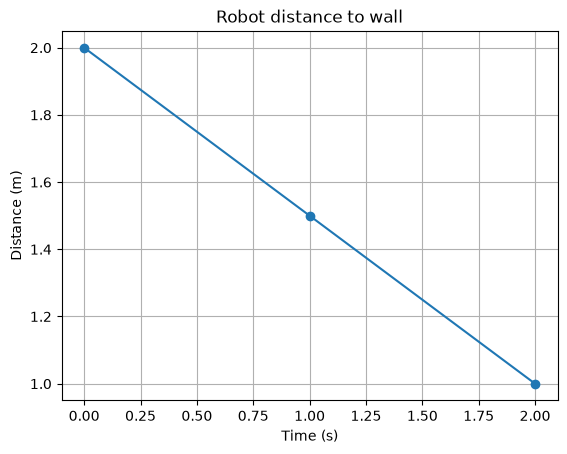

In [ ]:
import matplotlib.pyplot as plt

# 가로축: 시간(초)
times = [0, 1, 2]
# 세로축: 벽까지 남은 거리(m)
distances = [2.0, 1.5, 1.0]

plt.plot(times, distances, marker="o")  # 각 점을 선으로 연결
plt.xlabel("Time (s)")  # 가로축 이름
plt.ylabel("Distance (m)")  # 세로축 이름
plt.title("Robot distance to wall")  # 그래프 제목
plt.grid(True)  # 격자 표시
plt.show()  # 화면에 보여주기